# Retail Sales Forecasting During Structural Change

Author: Violetta Kalinicheva  
Original analysis: August 2026; portfolio validation: October 28, 2026

## Decision and analytical contract

Can a simple historical trend support planning when a sales series changes regime? One observation is one month of U.S. **retail trade sales excluding food services**, January 1992–June 2021, in **millions of nominal U.S. dollars**. Values are adjusted for seasonal, holiday, and trading-day differences, **not price changes**.

All 354 observed values have been reconstructed and matched exactly against four original Census archives. The default workflow downloads a pinned Census 2021 benchmark workbook and three later release PDFs; no course file, FRED download, account, or API key is required. Optional `PROJECT_DATA_DIR` accepts the unchanged original CSV. Source bytes and the canonical date/value sequence are hash-checked.

This is a **retrospective fixed-July-16-2021-vintage backtest**, not a real-time historical forecasting simulation. Revised historical inputs use information published after the validation and July 2020 test origins. Chronological target separation and training-only preprocessing are enforced, but historical publication-vintage leakage is not eliminated. The purpose is failure analysis of an interpretable baseline, not proof of deployable forecasting accuracy.

In [1]:
# I am limiting numerical workers so this full-data run remains resource-aware.
import os

for thread_variable in [
    "OMP_NUM_THREADS",
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "VECLIB_MAXIMUM_THREADS",
    "NUMEXPR_NUM_THREADS",
]:
    os.environ[thread_variable] = "4"
import time
import json
import hashlib
import platform
import importlib.metadata
from pathlib import Path
from threadpoolctl import threadpool_limits

threadpool_limits(limits=4)
get_ipython().run_line_magic("matplotlib", "inline")
run_started = time.monotonic()


def sha256_file(path):
    result = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(8 * 1024 * 1024), b""):
            result.update(block)
    return result.hexdigest()


source_notebook_sha256 = "6fa4ec96dad974c001dd0c274d64d91f2758c950e9bb7c630ec8d89d6c46f580"


In [2]:
# I am reconstructing the frozen series from original Census sources before any modeling.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from run import load_retail_source, numeric_digest

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", context="notebook")
retail_sales_raw, data_path, source_proof = load_retail_source()
source_manifest = json.loads(Path("sources.json").read_text())
assert numeric_digest(retail_sales_raw) == source_manifest["canonical_numeric_sha256"]
print("Verified direct Census numeric reconstruction: 354 of 354 observations match the original snapshot.")
print("Shape:", retail_sales_raw.shape)
print("Columns:", retail_sales_raw.columns.tolist())
print("Measure: retail trade excluding food services; nominal USD millions; seasonally adjusted.")
print("Fixed snapshot vintage: July 16, 2021; this is not a real-time-vintage backtest.")

Verified direct Census numeric reconstruction: 354 of 354 observations match the original snapshot.
Shape: (30, 13)
Columns: ['YEAR', 'JAN', 'FEB', 'MAR', 'APR', 'MAY', 'JUN', 'JUL', 'AUG', 'SEP', 'OCT', 'NOV', 'DEC']
Measure: retail trade excluding food services; nominal USD millions; seasonally adjusted.
Fixed snapshot vintage: July 16, 2021; this is not a real-time-vintage backtest.


In [3]:
# I am enforcing chronological target separation within the fixed July 2021 data vintage.
month_order = ["JAN", "FEB", "MAR", "APR", "MAY", "JUN", "JUL", "AUG", "SEP", "OCT", "NOV", "DEC"]
missing_values_before = int(retail_sales_raw[month_order].isna().sum().sum())
duplicate_years = int(retail_sales_raw.duplicated(subset="YEAR").sum())
retail_sales_long = retail_sales_raw.melt(
    id_vars="YEAR", value_vars=month_order, var_name="MONTH", value_name="Retail_Sales"
)
month_number = {month: number for number, month in enumerate(month_order, start=1)}
retail_sales_long["MONTH_NUMBER"] = retail_sales_long["MONTH"].map(month_number)
retail_sales_long["YEAR"] = pd.to_numeric(retail_sales_long["YEAR"], errors="raise")
retail_sales_long["Retail_Sales"] = pd.to_numeric(retail_sales_long["Retail_Sales"], errors="raise")
retail_sales_long["Date"] = pd.to_datetime(
    {"year": retail_sales_long["YEAR"], "month": retail_sales_long["MONTH_NUMBER"], "day": 1},
    errors="coerce",
)
retail_sales = (
    retail_sales_long.dropna(subset=["Date", "Retail_Sales"])
    .loc[:, ["Date", "Retail_Sales"]]
    .sort_values("Date")
    .reset_index(drop=True)
)
expected_dates = pd.date_range(start="1992-01-01", end="2021-06-01", freq="MS")
assert duplicate_years == 0, "Duplicate year records were found."
assert missing_values_before == 6, "Unexpected missing values were found."
assert len(retail_sales) == 354, "The cleaned dataset should contain 354 months."
assert (
    retail_sales["Date"].tolist() == expected_dates.tolist()
), "The monthly dates are incomplete or out of chronological order."
assert not retail_sales["Date"].duplicated().any(), "Duplicate monthly dates were found."
assert (
    retail_sales["Retail_Sales"].notna().all()
), "Missing retail sales values remain after cleaning."
assert (retail_sales["Retail_Sales"] >= 0).all(), "Negative retail sales values were found."
cleaning_summary = pd.DataFrame(
    {
        "Quality Check": [
            "Missing values in original monthly columns",
            "Duplicate yearly records",
            "Structural blanks removed",
            "Clean monthly observations",
            "Duplicate monthly dates after cleaning",
            "Missing sales values after cleaning",
        ],
        "Result": [
            missing_values_before,
            duplicate_years,
            len(retail_sales_long) - len(retail_sales),
            len(retail_sales),
            int(retail_sales["Date"].duplicated().sum()),
            int(retail_sales["Retail_Sales"].isna().sum()),
        ],
    }
)
print("Data Quality and Cleaning Summary:")
display(cleaning_summary)
print("\nFirst Five Monthly Observations:")
display(retail_sales.head())
print("\nLast Five Monthly Observations:")
display(retail_sales.tail())
print(
    f"\nClean Date Range: {retail_sales['Date'].min():%B %Y} through {retail_sales['Date'].max():%B %Y}"
)


Data Quality and Cleaning Summary:


,Quality Check,Result
0,Missing values in original monthly columns,6
1,Duplicate yearly records,0
2,Structural blanks removed,6
3,Clean monthly observations,354
4,Duplicate monthly dates after cleaning,0
5,Missing sales values after cleaning,0



First Five Monthly Observations:


,Date,Retail_Sales
0,1992-01-01,"146,925.00"
1,1992-02-01,"147,223.00"
2,1992-03-01,"146,805.00"
3,1992-04-01,"148,032.00"
4,1992-05-01,"149,010.00"



Last Five Monthly Observations:


,Date,Retail_Sales
349,2021-02-01,"504,458.00"
350,2021-03-01,"559,871.00"
351,2021-04-01,"562,269.00"
352,2021-05-01,"548,987.00"
353,2021-06-01,"550,782.00"



Clean Date Range: January 1992 through June 2021


### Section 2 Interpretation

The data-cleaning process produced a complete time series of 354 consecutive monthly observations from January 1992 through June 2021. The six missing values in the original file represented July through December 2021, which are outside the dataset’s stated coverage, so removing them did not eliminate any observed sales data. No duplicate dates or remaining missing sales values were identified. Therefore, the cleaned dataset is chronologically complete and can be used for time-series visualization and modeling without imputation.

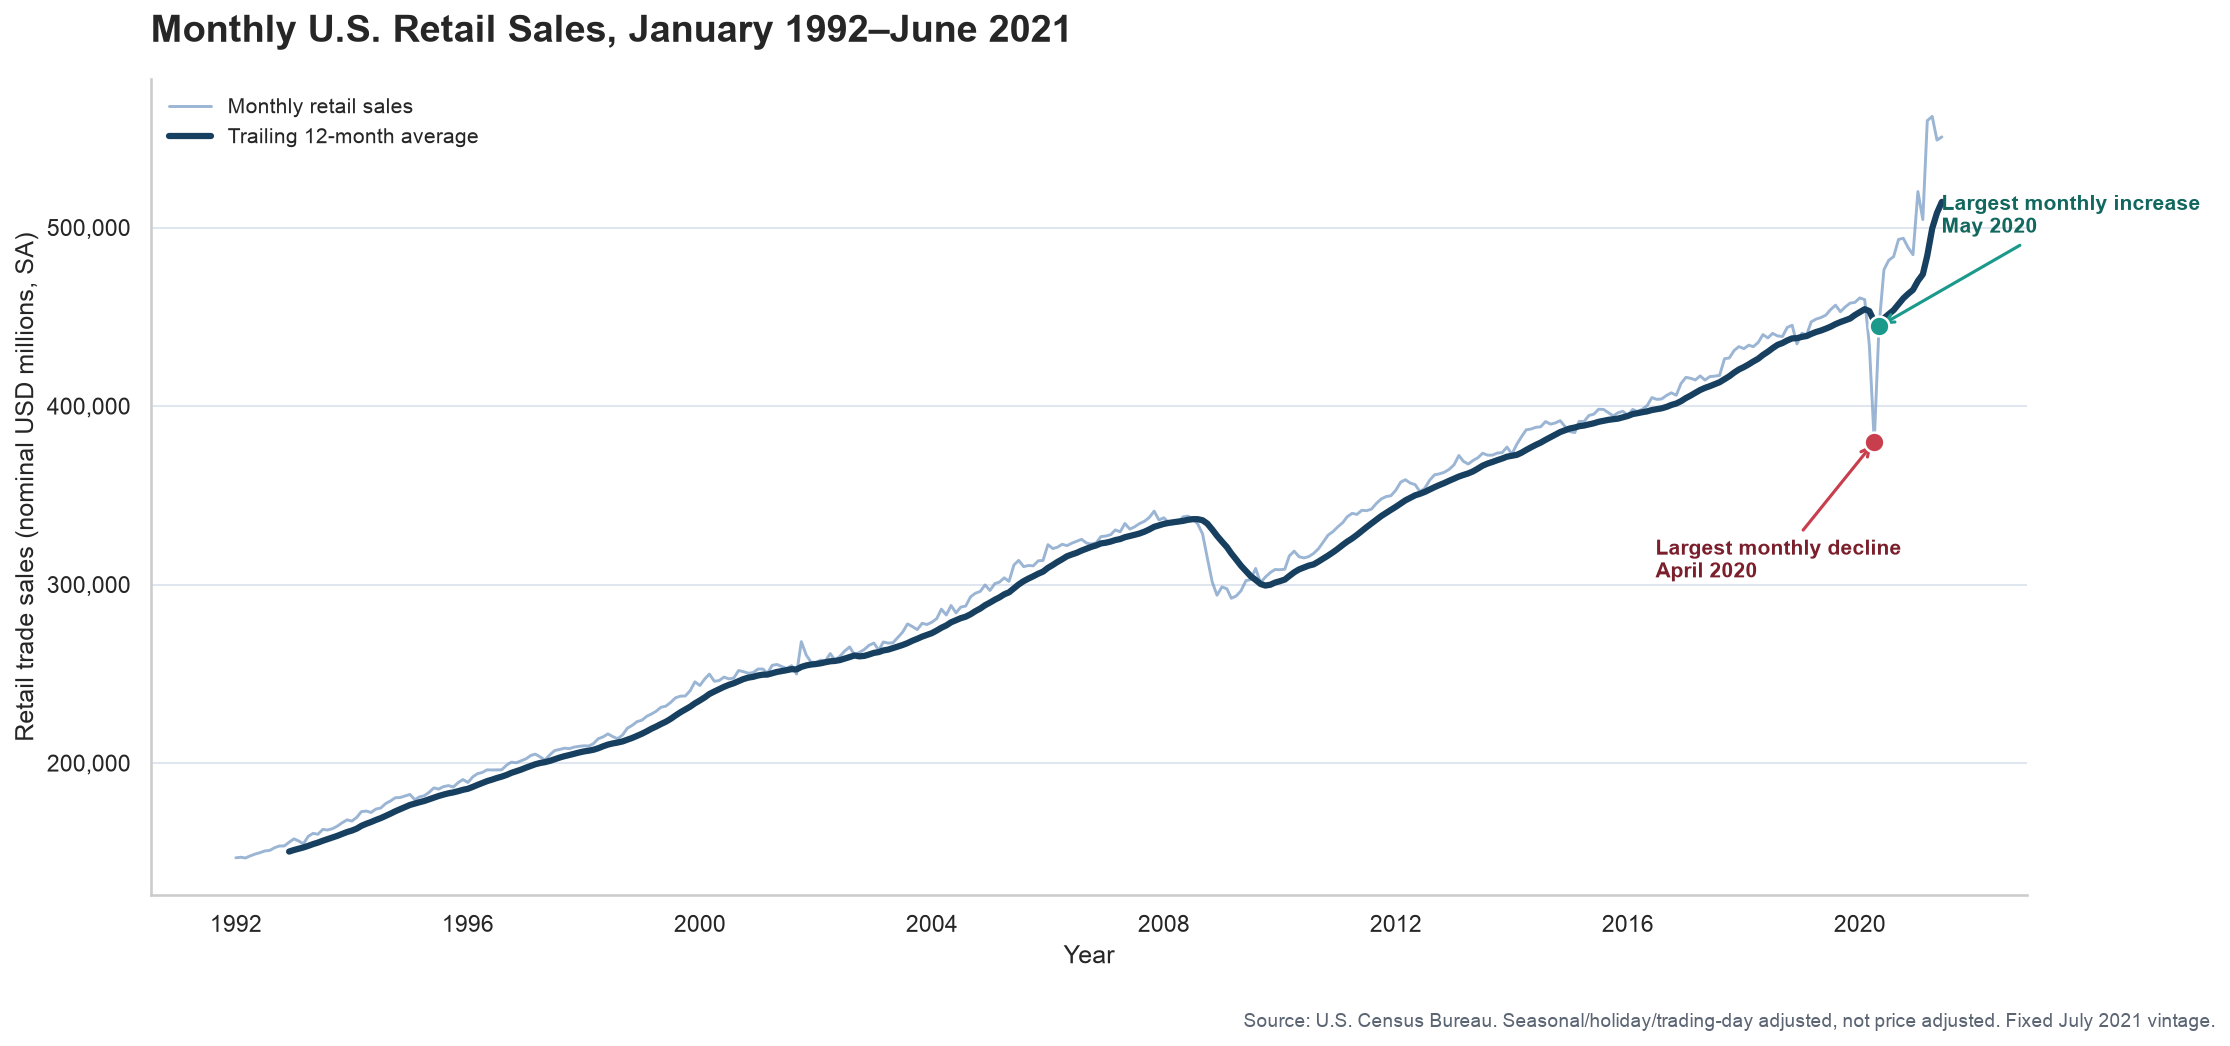

Visualization Summary:


,Measure,Result
0,First monthly sales value,"146,925"
1,Last monthly sales value,"550,782"
2,Overall percentage change,274.9%
3,Largest monthly decline,"-54,389 (April 2020)"
4,Largest monthly increase,"+64,739 (May 2020)"


In [4]:
# I am enforcing chronological target separation within the fixed July 2021 data vintage.
retail_sales_plot = retail_sales.copy()
retail_sales_plot["Rolling_12_Month_Average"] = (
    retail_sales_plot["Retail_Sales"].rolling(window=12).mean()
)
retail_sales_plot["Monthly_Change"] = retail_sales_plot["Retail_Sales"].diff()
largest_decline = retail_sales_plot.loc[retail_sales_plot["Monthly_Change"].idxmin()]
largest_increase = retail_sales_plot.loc[retail_sales_plot["Monthly_Change"].idxmax()]
overall_change_percent = (
    retail_sales_plot["Retail_Sales"].iloc[-1] / retail_sales_plot["Retail_Sales"].iloc[0] - 1
) * 100
import matplotlib.dates as mdates
import matplotlib.ticker as mticker

fig, ax = plt.subplots(figsize=(15, 7), dpi=150)
ax.plot(
    retail_sales_plot["Date"],
    retail_sales_plot["Retail_Sales"],
    color="#7A9CC6",
    linewidth=1.4,
    alpha=0.75,
    label="Monthly retail sales",
)
ax.plot(
    retail_sales_plot["Date"],
    retail_sales_plot["Rolling_12_Month_Average"],
    color="#173F5F",
    linewidth=3,
    label="Trailing 12-month average",
)
ax.scatter(
    largest_decline["Date"],
    largest_decline["Retail_Sales"],
    color="#C83E4D",
    edgecolor="white",
    linewidth=1.2,
    s=90,
    zorder=5,
)
ax.annotate(
    f"Largest monthly decline\n{largest_decline['Date']:%B %Y}",
    xy=(largest_decline["Date"], largest_decline["Retail_Sales"]),
    xytext=(-105, -65),
    textcoords="offset points",
    fontsize=10,
    color="#7A1F2B",
    fontweight="bold",
    arrowprops={"arrowstyle": "->", "color": "#C83E4D", "linewidth": 1.5},
)
ax.scatter(
    largest_increase["Date"],
    largest_increase["Retail_Sales"],
    color="#1B998B",
    edgecolor="white",
    linewidth=1.2,
    s=90,
    zorder=5,
)
ax.annotate(
    f"Largest monthly increase\n{largest_increase['Date']:%B %Y}",
    xy=(largest_increase["Date"], largest_increase["Retail_Sales"]),
    xytext=(30, 45),
    textcoords="offset points",
    fontsize=10,
    color="#12685F",
    fontweight="bold",
    arrowprops={"arrowstyle": "->", "color": "#1B998B", "linewidth": 1.5},
)
ax.set_title(
    "Monthly U.S. Retail Sales, January 1992–June 2021",
    fontsize=18,
    fontweight="bold",
    loc="left",
    pad=18,
)
ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Retail trade sales (nominal USD millions, SA)", fontsize=12)
ax.xaxis.set_major_locator(mdates.YearLocator(base=4))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y", color="#D9E2EC", linewidth=0.8)
ax.grid(axis="x", visible=False)
sns.despine(ax=ax)
ax.legend(loc="upper left", frameon=False, fontsize=10)
fig.text(
    0.99,
    0.01,
    "Source: U.S. Census Bureau. Seasonal/holiday/trading-day adjusted, not price adjusted. Fixed July 2021 vintage.",
    ha="right",
    fontsize=9,
    color="#5B6573",
)
plt.tight_layout(rect=[0, 0.04, 1, 1])
Path("outputs").mkdir(exist_ok=True)
fig.savefig("outputs/01_monthly_sales.png", dpi=150, bbox_inches="tight")
plt.show()
visualization_summary = pd.DataFrame(
    {
        "Measure": [
            "First monthly sales value",
            "Last monthly sales value",
            "Overall percentage change",
            "Largest monthly decline",
            "Largest monthly increase",
        ],
        "Result": [
            f"{retail_sales_plot['Retail_Sales'].iloc[0]:,.0f}",
            f"{retail_sales_plot['Retail_Sales'].iloc[-1]:,.0f}",
            f"{overall_change_percent:,.1f}%",
            f"{largest_decline['Monthly_Change']:,.0f} ({largest_decline['Date']:%B %Y})",
            f"+{largest_increase['Monthly_Change']:,.0f} ({largest_increase['Date']:%B %Y})",
        ],
    }
)
print("Visualization Summary:")
display(visualization_summary)


### Section 3 Interpretation

Nominal seasonally adjusted retail trade sales rise from 146,925 million dollars in January 1992 to 550,782 million dollars in June 2021, a 274.9% nominal increase. This is **not real purchasing-power growth**. The largest monthly decline is 54,389 million dollars in April 2020, followed by an increase of 64,739 million in May 2020. These observations motivate checking a regime-change failure rather than assuming a stable historical pattern.

Training and Test Set Summary:


,Dataset,Start Date,End Date,Monthly Observations
0,Training Set,January 1992,June 2020,342
1,Test Set,July 2020,June 2021,12


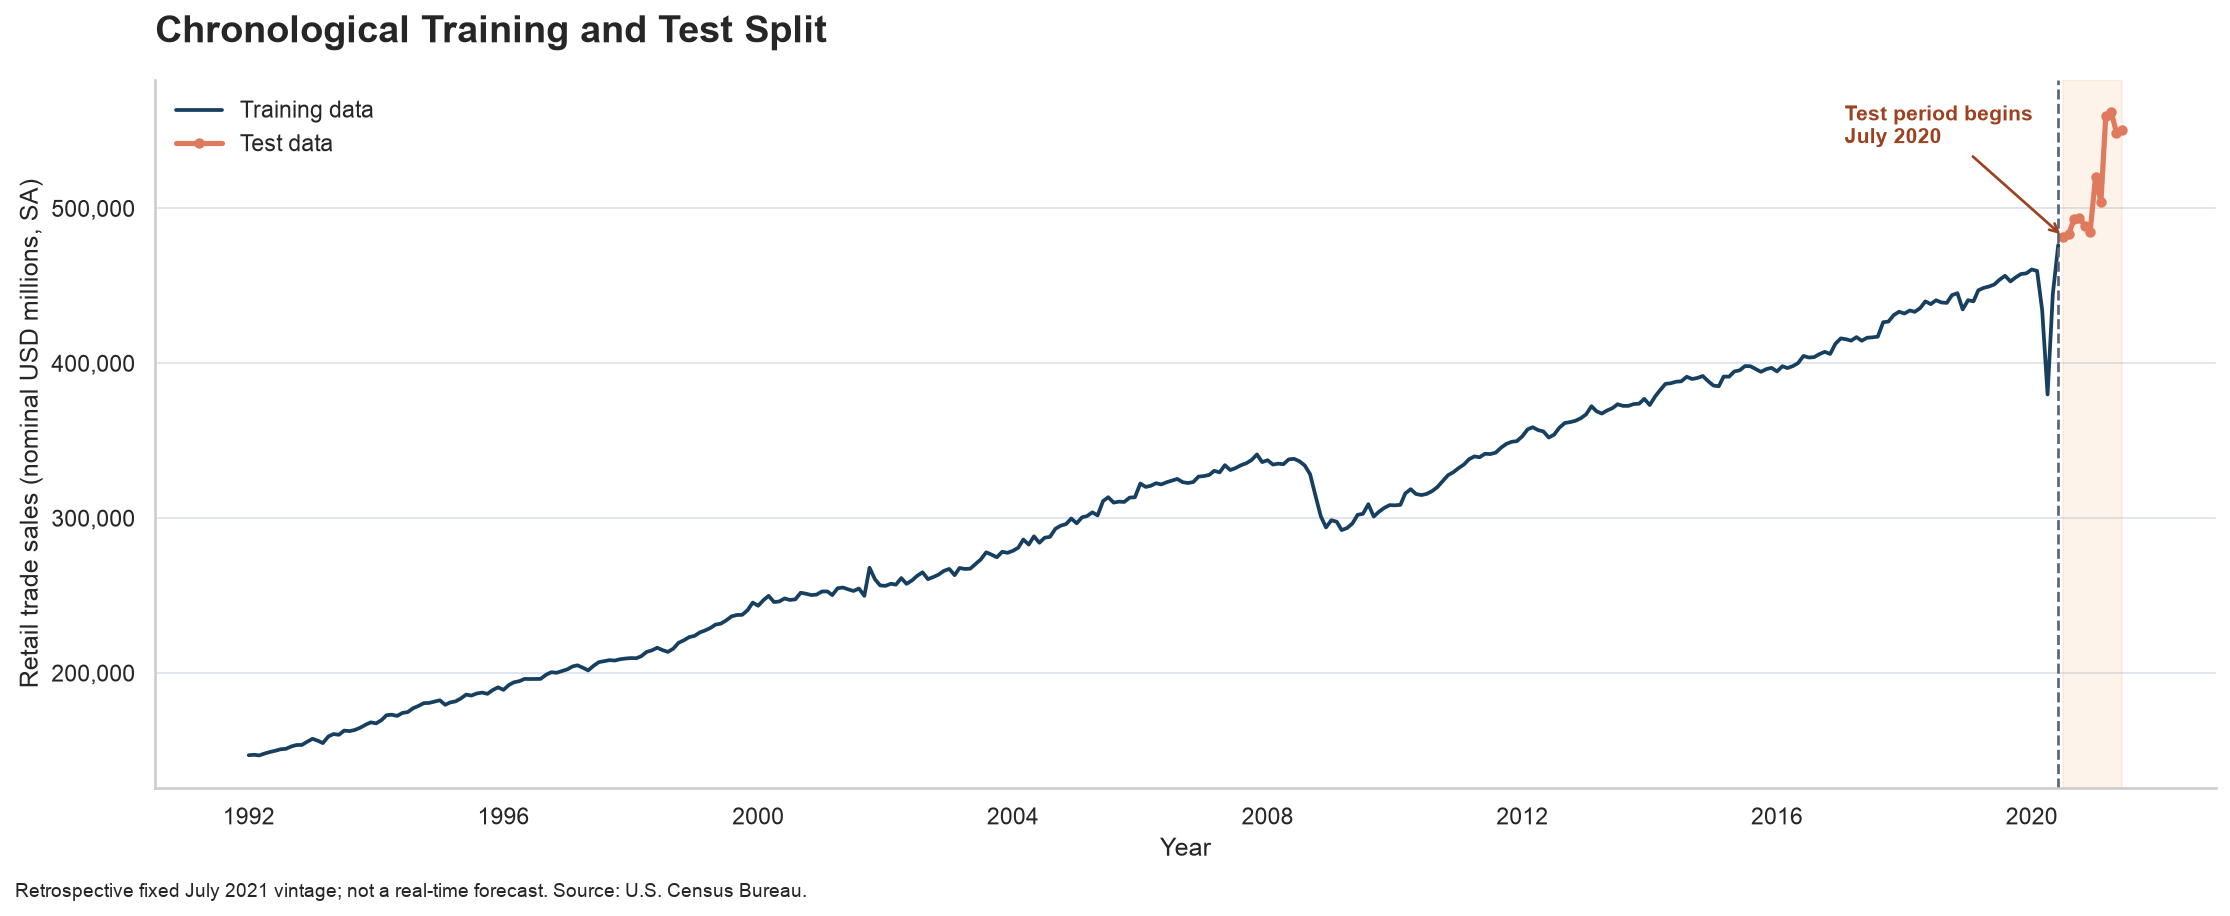

In [5]:
# I am enforcing chronological target separation within the fixed July 2021 data vintage.
training_end_date = pd.Timestamp("2020-06-01")
test_start_date = pd.Timestamp("2020-07-01")
test_end_date = pd.Timestamp("2021-06-01")
training_data = retail_sales.loc[retail_sales["Date"] <= training_end_date].copy()
test_data = retail_sales.loc[retail_sales["Date"].between(test_start_date, test_end_date)].copy()
training_series = training_data.set_index("Date")["Retail_Sales"].asfreq("MS")
test_series = test_data.set_index("Date")["Retail_Sales"].asfreq("MS")
assert len(training_data) == 342, "The training set should contain 342 monthly observations."
assert len(test_data) == 12, "The test set should contain exactly 12 monthly observations."
assert training_data["Date"].max() == training_end_date, "The training set must end in June 2020."
assert test_data["Date"].min() == test_start_date, "The test set must begin in July 2020."
assert test_data["Date"].max() == test_end_date, "The test set must end in June 2021."
assert (
    training_data["Date"].max() < test_data["Date"].min()
), "The training and test periods overlap."
assert training_series.notna().all(), "The training series contains missing values."
assert test_series.notna().all(), "The test series contains missing values."
split_summary = pd.DataFrame(
    {
        "Dataset": ["Training Set", "Test Set"],
        "Start Date": [
            training_data["Date"].min().strftime("%B %Y"),
            test_data["Date"].min().strftime("%B %Y"),
        ],
        "End Date": [
            training_data["Date"].max().strftime("%B %Y"),
            test_data["Date"].max().strftime("%B %Y"),
        ],
        "Monthly Observations": [len(training_data), len(test_data)],
    }
)
print("Training and Test Set Summary:")
display(split_summary)
fig, ax = plt.subplots(figsize=(15, 6), dpi=150)
ax.plot(
    training_data["Date"],
    training_data["Retail_Sales"],
    color="#173F5F",
    linewidth=1.8,
    label="Training data",
)
ax.plot(
    test_data["Date"],
    test_data["Retail_Sales"],
    color="#E07A5F",
    linewidth=2.5,
    marker="o",
    markersize=4,
    label="Test data",
)
ax.axvspan(test_start_date, test_end_date, color="#F4A261", alpha=0.12)
ax.axvline(training_end_date, color="#5B6573", linestyle="--", linewidth=1.3)
ax.annotate(
    "Test period begins\nJuly 2020",
    xy=(test_start_date, test_data["Retail_Sales"].iloc[0]),
    xytext=(-105, 45),
    textcoords="offset points",
    fontsize=10,
    fontweight="bold",
    color="#9C4221",
    arrowprops={"arrowstyle": "->", "color": "#9C4221", "linewidth": 1.3},
)
ax.set_title(
    "Chronological Training and Test Split", fontsize=18, fontweight="bold", loc="left", pad=18
)
ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Retail trade sales (nominal USD millions, SA)", fontsize=12)
ax.xaxis.set_major_locator(mdates.YearLocator(base=4))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y", color="#D9E2EC", linewidth=0.8)
ax.grid(axis="x", visible=False)
sns.despine(ax=ax)
ax.legend(loc="upper left", frameon=False)
fig.text(.01, -.01, "Retrospective fixed July 2021 vintage; not a real-time forecast. Source: U.S. Census Bureau.", fontsize=9)
plt.tight_layout()
Path("outputs").mkdir(exist_ok=True)
fig.savefig("outputs/02_chronological_split.png", dpi=150, bbox_inches="tight")
plt.show()


### Section 4 Interpretation

The split contains 342 training months through June 2020 and twelve test months from July 2020 through June 2021. No test targets enter model fitting or selection. However, every period uses a July 2021 data vintage, so historical values have been revised after the nominal forecast origins. This is a valid fixed-vintage retrospective comparison, **not a demonstration of what an analyst could have forecast using information actually published in July 2020**.

In [6]:
# I am enforcing chronological target separation within the fixed July 2021 data vintage.
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error

training_model_data = training_data.copy()
training_model_data["Time_Index"] = (
    (training_model_data["Date"].dt.year - 1992) * 12 + training_model_data["Date"].dt.month - 1
)
training_model_data["Month"] = training_model_data["Date"].dt.month.astype(str)


def calculate_rmse(actual_values, predicted_values):
    return np.sqrt(mean_squared_error(actual_values, predicted_values))


validation_starts = pd.to_datetime(
    ["2015-07-01", "2016-07-01", "2017-07-01", "2018-07-01", "2019-07-01"]
)
validation_results = []
for validation_start in validation_starts:
    validation_end = validation_start + pd.DateOffset(months=11)
    fold_training = training_model_data.loc[training_model_data["Date"] < validation_start].copy()
    fold_validation = training_model_data.loc[
        training_model_data["Date"].between(validation_start, validation_end)
    ].copy()
    assert (
        len(fold_validation) == 12
    ), "Each validation period must contain 12 monthly observations."
    linear_trend_model = LinearRegression()
    linear_trend_model.fit(fold_training[["Time_Index"]], fold_training["Retail_Sales"])
    linear_trend_predictions = linear_trend_model.predict(fold_validation[["Time_Index"]])
    validation_results.append(
        {
            "Validation Period": f"{validation_start:%b %Y}–{validation_end:%b %Y}",
            "Model": "Linear Trend",
            "RMSE": calculate_rmse(fold_validation["Retail_Sales"], linear_trend_predictions),
        }
    )
    seasonal_preprocessor = ColumnTransformer(
        transformers=[
            ("time", "passthrough", ["Time_Index"]),
            ("month", OneHotEncoder(drop="first", handle_unknown="ignore"), ["Month"]),
        ]
    )
    seasonal_trend_model = Pipeline(
        steps=[("preprocessor", seasonal_preprocessor), ("regression", LinearRegression())]
    )
    seasonal_trend_model.fit(fold_training[["Time_Index", "Month"]], fold_training["Retail_Sales"])
    seasonal_trend_predictions = seasonal_trend_model.predict(
        fold_validation[["Time_Index", "Month"]]
    )
    validation_results.append(
        {
            "Validation Period": f"{validation_start:%b %Y}–{validation_end:%b %Y}",
            "Model": "Linear Trend + Month Seasonality",
            "RMSE": calculate_rmse(fold_validation["Retail_Sales"], seasonal_trend_predictions),
        }
    )
    seasonal_naive_predictions = fold_training["Retail_Sales"].iloc[-12:].to_numpy()
    validation_results.append(
        {
            "Validation Period": f"{validation_start:%b %Y}–{validation_end:%b %Y}",
            "Model": "Seasonal Naive",
            "RMSE": calculate_rmse(fold_validation["Retail_Sales"], seasonal_naive_predictions),
        }
    )
validation_results = pd.DataFrame(validation_results)
model_comparison = (
    validation_results.groupby("Model")["RMSE"]
    .agg(Average_RMSE="mean", RMSE_Standard_Deviation="std")
    .sort_values("Average_RMSE")
    .reset_index()
)
model_comparison_display = model_comparison.copy()
model_comparison_display[["Average_RMSE", "RMSE_Standard_Deviation"]] = (
    model_comparison_display[["Average_RMSE", "RMSE_Standard_Deviation"]].round(0).astype(int)
)
print("Rolling 12-Month Validation Results:")
display(model_comparison_display)
selected_model_name = model_comparison.loc[0, "Model"]
print(f"Selected Forecasting Model: {selected_model_name}")
if selected_model_name == "Linear Trend":
    selected_model = LinearRegression()
    selected_model.fit(training_model_data[["Time_Index"]], training_model_data["Retail_Sales"])
elif selected_model_name == "Linear Trend + Month Seasonality":
    final_preprocessor = ColumnTransformer(
        transformers=[
            ("time", "passthrough", ["Time_Index"]),
            ("month", OneHotEncoder(drop="first", handle_unknown="ignore"), ["Month"]),
        ]
    )
    selected_model = Pipeline(
        steps=[("preprocessor", final_preprocessor), ("regression", LinearRegression())]
    )
    selected_model.fit(
        training_model_data[["Time_Index", "Month"]], training_model_data["Retail_Sales"]
    )
else:
    selected_model = None
print(f"Model fitted using {len(training_model_data)} training observations.")


Rolling 12-Month Validation Results:


,Model,Average_RMSE,RMSE_Standard_Deviation
0,Linear Trend,11343,8800
1,Linear Trend + Month Seasonality,11370,8834
2,Seasonal Naive,16301,6656


Selected Forecasting Model: Linear Trend
Model fitted using 342 training observations.


### Section 5 Interpretation

The linear-trend model achieved the lowest average validation RMSE at 11,343, narrowly outperforming the trend-plus-seasonality model at 11,370 and performing substantially better than the seasonal-naive benchmark at 16,301. Because adding monthly seasonal effects did not meaningfully improve accuracy, the simpler linear-trend model was selected and fitted using all 342 training observations. The RMSE standard deviation of 8,800 indicates that forecast accuracy varied considerably across validation years, so performance may be less reliable during unusually volatile periods.

Test-Set Predictions:


,Date,Actual_Sales,Predicted_Sales,Error,Absolute_Error
0,July 2020,481627,449458,32169,32169
1,August 2020,483716,450331,33385,33385
2,September 2020,493327,451204,42123,42123
3,October 2020,493991,452077,41914,41914
4,November 2020,488652,452950,35702,35702
5,December 2020,484782,453823,30959,30959
6,January 2021,520162,454696,65466,65466
7,February 2021,504458,455569,48889,48889
8,March 2021,559871,456442,103429,103429
9,April 2021,562269,457315,104954,104954



Final Test-Set Performance:


,Performance Measure,Result
0,Selected Model,Linear Trend
1,Test Observations,12
2,Test RMSE,"66,433"
3,Test MAE,"60,126"
4,RMSE as Percentage of Mean Actual Sales,12.9%


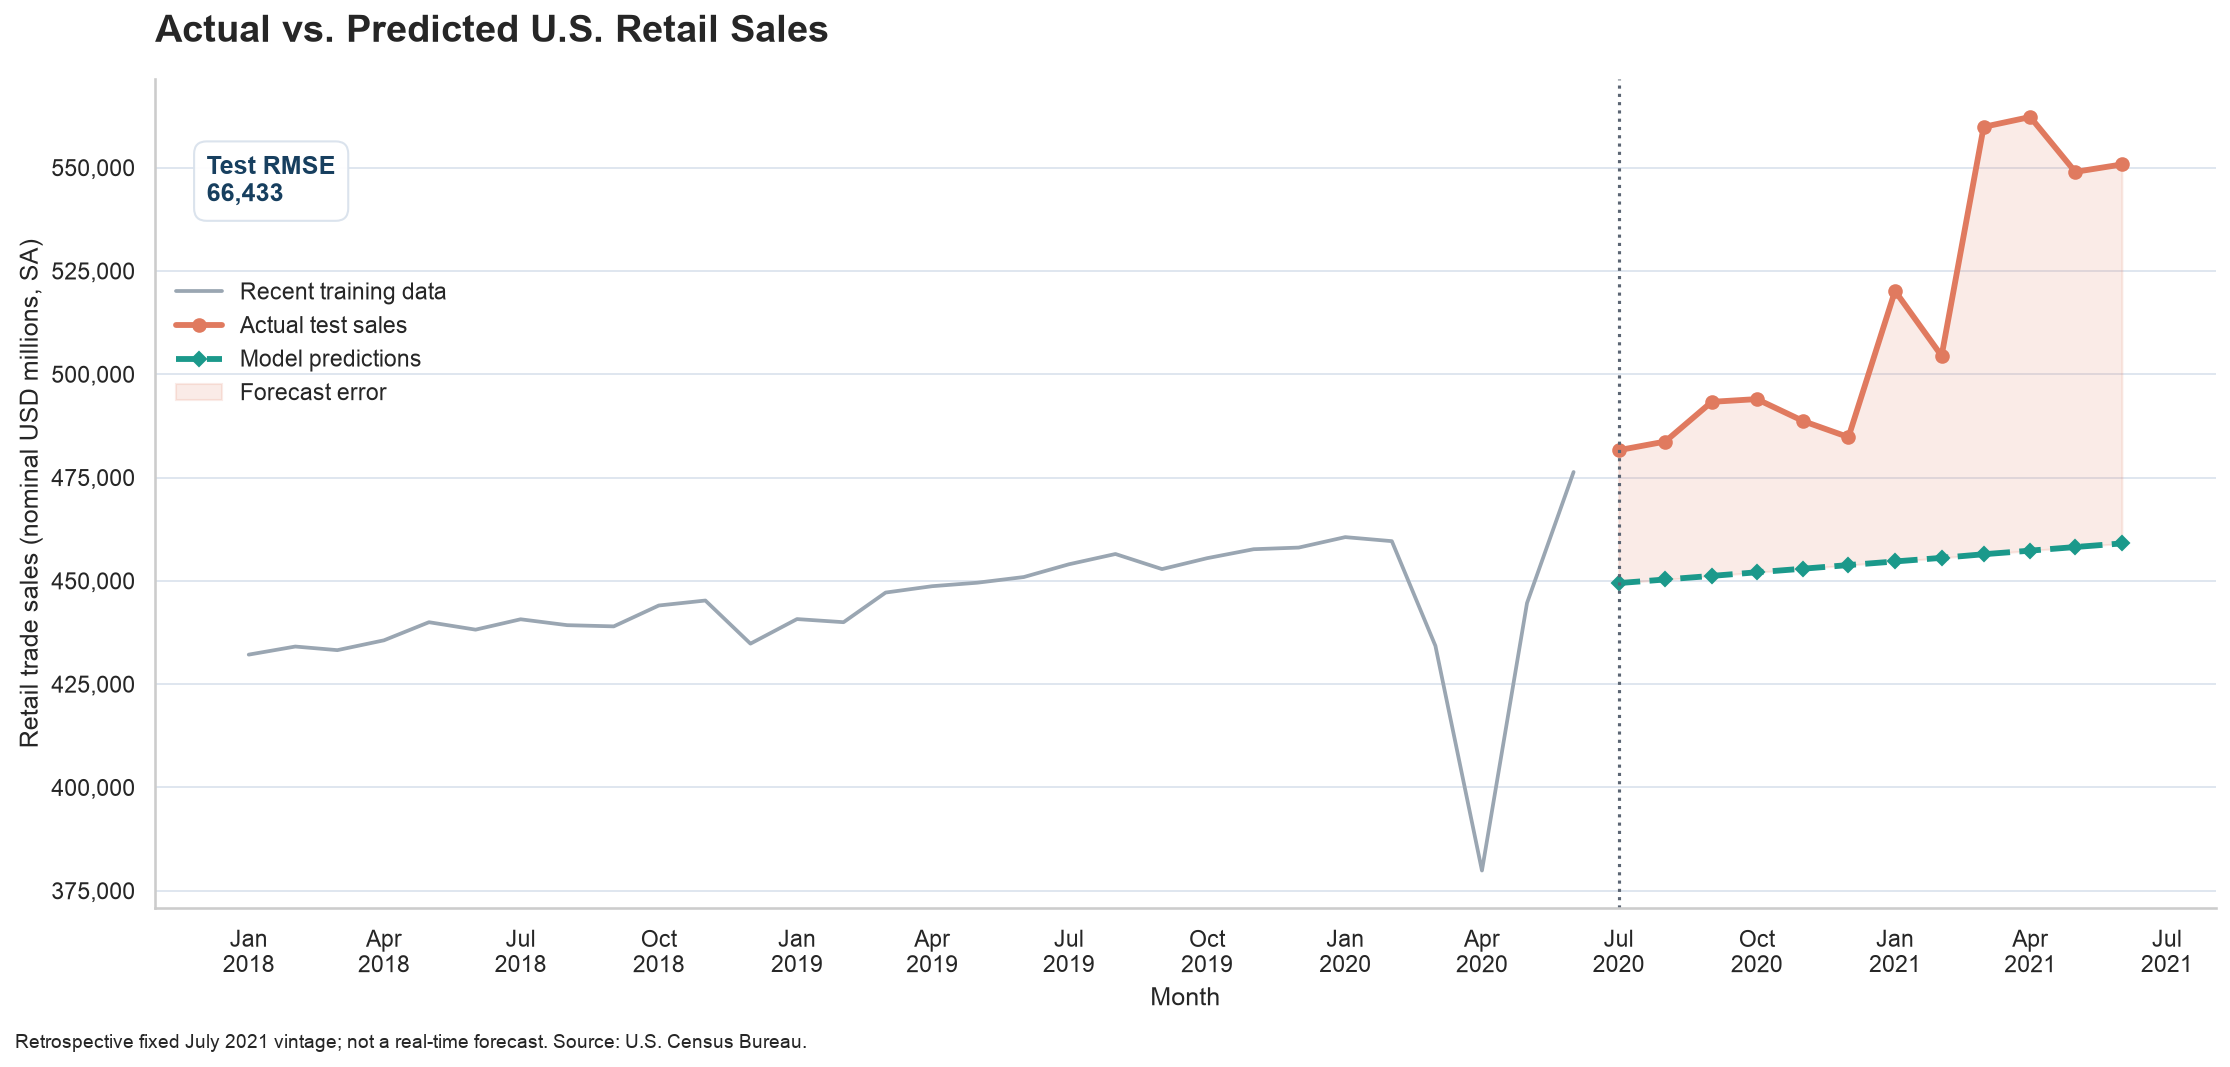

In [7]:
# I am enforcing chronological target separation within the fixed July 2021 data vintage.
test_model_data = test_data.copy()
test_model_data["Time_Index"] = (
    (test_model_data["Date"].dt.year - 1992) * 12 + test_model_data["Date"].dt.month - 1
)
test_model_data["Month"] = test_model_data["Date"].dt.month.astype(str)
if selected_model_name == "Linear Trend":
    test_predictions = selected_model.predict(test_model_data[["Time_Index"]])
elif selected_model_name == "Linear Trend + Month Seasonality":
    test_predictions = selected_model.predict(test_model_data[["Time_Index", "Month"]])
else:
    test_predictions = training_model_data["Retail_Sales"].iloc[-12:].to_numpy()
prediction_results = pd.DataFrame(
    {
        "Date": test_model_data["Date"].to_numpy(),
        "Actual_Sales": test_model_data["Retail_Sales"].to_numpy(),
        "Predicted_Sales": test_predictions,
    }
)
prediction_results["Error"] = (
    prediction_results["Actual_Sales"] - prediction_results["Predicted_Sales"]
)
prediction_results["Absolute_Error"] = prediction_results["Error"].abs()
assert len(prediction_results) == 12, "There must be exactly 12 test-set predictions."
assert (
    prediction_results["Predicted_Sales"].notna().all()
), "One or more model predictions are missing."
assert np.isfinite(
    prediction_results["Predicted_Sales"]
).all(), "One or more model predictions are not finite."
test_rmse = calculate_rmse(
    prediction_results["Actual_Sales"], prediction_results["Predicted_Sales"]
)
test_mae = prediction_results["Absolute_Error"].mean()
normalized_rmse = test_rmse / prediction_results["Actual_Sales"].mean() * 100
prediction_table = prediction_results.copy()
prediction_table["Date"] = prediction_table["Date"].dt.strftime("%B %Y")
prediction_table[["Actual_Sales", "Predicted_Sales", "Error", "Absolute_Error"]] = (
    prediction_table[["Actual_Sales", "Predicted_Sales", "Error", "Absolute_Error"]]
    .round(0)
    .astype(int)
)
print("Test-Set Predictions:")
display(prediction_table)
performance_summary = pd.DataFrame(
    {
        "Performance Measure": [
            "Selected Model",
            "Test Observations",
            "Test RMSE",
            "Test MAE",
            "RMSE as Percentage of Mean Actual Sales",
        ],
        "Result": [
            selected_model_name,
            len(prediction_results),
            f"{test_rmse:,.0f}",
            f"{test_mae:,.0f}",
            f"{normalized_rmse:.1f}%",
        ],
    }
)
print("\nFinal Test-Set Performance:")
display(performance_summary)
forecast_context = training_data.tail(30)
fig, ax = plt.subplots(figsize=(15, 7), dpi=150)
ax.plot(
    forecast_context["Date"],
    forecast_context["Retail_Sales"],
    color="#9AA6B2",
    linewidth=1.8,
    label="Recent training data",
)
ax.plot(
    prediction_results["Date"],
    prediction_results["Actual_Sales"],
    color="#E07A5F",
    linewidth=2.8,
    marker="o",
    markersize=6,
    label="Actual test sales",
)
ax.plot(
    prediction_results["Date"],
    prediction_results["Predicted_Sales"],
    color="#1B998B",
    linewidth=2.8,
    linestyle="--",
    marker="D",
    markersize=5,
    label="Model predictions",
)
ax.fill_between(
    prediction_results["Date"],
    prediction_results["Actual_Sales"],
    prediction_results["Predicted_Sales"],
    color="#E07A5F",
    alpha=0.15,
    label="Forecast error",
)
ax.axvline(test_start_date, color="#5B6573", linestyle=":", linewidth=1.5)
ax.text(
    0.025,
    0.91,
    f"Test RMSE\n{test_rmse:,.0f}",
    transform=ax.transAxes,
    fontsize=12,
    fontweight="bold",
    color="#173F5F",
    verticalalignment="top",
    bbox={"boxstyle": "round,pad=0.5", "facecolor": "white", "edgecolor": "#D9E2EC", "alpha": 0.95},
)
ax.set_title(
    "Actual vs. Predicted U.S. Retail Sales", fontsize=18, fontweight="bold", loc="left", pad=18
)
ax.set_xlabel("Month", fontsize=12)
ax.set_ylabel("Retail trade sales (nominal USD millions, SA)", fontsize=12)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y", color="#D9E2EC", linewidth=0.8)
ax.grid(axis="x", visible=False)
sns.despine(ax=ax)
ax.legend(loc="upper left", bbox_to_anchor=(0, 0.78), frameon=False)
fig.text(.01, -.01, "Retrospective fixed July 2021 vintage; not a real-time forecast. Source: U.S. Census Bureau.", fontsize=9)
plt.tight_layout()
Path("outputs").mkdir(exist_ok=True)
fig.savefig("outputs/03_forecast_failure.png", dpi=150, bbox_inches="tight")
plt.show()


### Section 6 Interpretation

The selected trend model's test RMSE is **66,433 million nominal dollars**, and MAE is **60,126 million**. RMSE is 12.9% of mean test sales, a normalized error rather than MAPE. The model underpredicts all twelve test months. Its test RMSE is 5.86 times the mean historical validation RMSE. This failure is observed within the verified fixed July 2021 vintage; it does not measure real-time forecasting performance or identify the cause of the regime change.

## Section 7. Final conclusion and decision

The baseline fails transparently in the held-out year: a simple linear trend misses the higher level of nominal retail sales in all twelve months. Its low average historical validation RMSE did not guarantee stability in this shifted period. A planning analyst should monitor signed error, review structural change, and require a separate later evaluation before adopting an alternative.

Three limits matter for action. First, these are nominal seasonally adjusted **retail trade** sales, excluding food services, not inflation-adjusted consumer spending. Second, a single test year cannot establish long-run generalization or prediction-interval coverage. Third, the fixed July 2021 revision vintage means these historical inputs were not all available at the nominal forecast origins. A production study would repeat the design using an archived data vintage available at each origin, then evaluate subsequent revisions and realized forecasting performance. No causal explanation or current forecast is claimed.

## References and provenance

U.S. Census Bureau. (2021). [2021 annual revision of monthly retail and food services](https://www.census.gov/retail/mrts/historic_releases.html), benchmark workbook, followed by the May 14, June 15, and July 16 archived advance monthly retail releases. These four original Census sources reconstruct all 354 values; URLs, hashes, exact row/column mapping, and revision order are in `sources.json`.

U.S. Census Bureau. [Monthly retail time-series definitions](https://www.census.gov/retail/marts/www/timeseries.html). The archived July 2021 release specifies millions of dollars, seasonal/holiday/trading-day adjustment, and no price adjustment. Sources and the [Census DS027 policy, p. 9](https://www2.census.gov/foia/ds_policies/ds027.pdf) checked October 28, 2026. Government-produced statistical data are attributed; no raw archives are redistributed and no endorsement is implied.

[FRED RSXFS metadata](https://fred.stlouisfed.org/series/RSXFS) independently corroborate series identity. FRED/ALFRED content is **not an acquisition dependency**; the executable workflow uses original Census archives only.

Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3rd ed.), [The forecaster's toolbox](https://otexts.com/fpp3/toolbox.html). This supports time-series cross-validation and forecast-error evaluation, not a real-time-vintage performance claim.

## 8. Baseline comparison and uncertainty boundary

All three predeclared methods are reported on the same twelve held-out months for diagnostic comparison, not a second round of selection. A single test year is not twelve independent experiments. RMSE divided by mean actual sales is a normalization, not MAPE. Source identity and unit are now verified, but all folds use the **July 16, 2021 revision vintage**, which postdates their origins. Therefore this is not a real-time-vintage backtest. No prediction interval is claimed; historical model-error variability is in the fold table, and a structural shift makes naive historical intervals unreliable.

In [8]:
# I am checking baseline errors and recording the full-data run, not hiding the failure year.
test_baselines = []
for name in ["Linear Trend", "Linear Trend + Month Seasonality", "Seasonal Naive"]:
    if name == "Seasonal Naive":
        predicted = training_model_data.Retail_Sales.iloc[-12:].to_numpy()
    elif name == "Linear Trend":
        diagnostic_model = LinearRegression().fit(
            training_model_data[["Time_Index"]], training_model_data.Retail_Sales
        )
        predicted = diagnostic_model.predict(test_model_data[["Time_Index"]])
    else:
        diagnostic_model = Pipeline(
            [
                (
                    "prepare",
                    ColumnTransformer(
                        [
                            ("time", "passthrough", ["Time_Index"]),
                            (
                                "month",
                                OneHotEncoder(drop="first", handle_unknown="ignore"),
                                ["Month"],
                            ),
                        ]
                    ),
                ),
                ("regression", LinearRegression()),
            ]
        )
        diagnostic_model.fit(
            training_model_data[["Time_Index", "Month"]], training_model_data.Retail_Sales
        )
        predicted = diagnostic_model.predict(test_model_data[["Time_Index", "Month"]])
    test_baselines.append(
        {
            "model": name,
            "rmse": float(calculate_rmse(test_model_data.Retail_Sales, predicted)),
            "mae": float(np.mean(np.abs(test_model_data.Retail_Sales.to_numpy() - predicted))),
        }
    )
display(pd.DataFrame(test_baselines).round(2))
assert retail_sales_raw.columns.tolist() == ["YEAR"] + month_order
assert retail_sales_raw.YEAR.is_unique
structural_blank_rows = retail_sales_long.loc[retail_sales_long.Retail_Sales.isna()]
assert structural_blank_rows.Date.min() == pd.Timestamp("2021-07-01")
assert structural_blank_rows.Date.max() == pd.Timestamp("2021-12-01")
validation = {
    "project": "Retail Sales Forecasting During Structural Change",
    "validated_on": "2026-10-28",
    "source_notebook_sha256": source_notebook_sha256,
    "raw_sha256": {"us_retail_sales.csv": sha256_file(data_path)},
    "audit": {
        "raw_year_rows": len(retail_sales_raw),
        "raw_month_cells": len(retail_sales_long),
        "structural_blanks": missing_values_before,
        "retained_months": len(retail_sales),
        "duplicates": duplicate_years,
        "start": str(retail_sales.Date.min().date()),
        "end": str(retail_sales.Date.max().date()),
        "first_value": float(retail_sales.Retail_Sales.iloc[0]),
        "last_value": float(retail_sales.Retail_Sales.iloc[-1]),
    },
    "design": {
        "training_months": len(training_data),
        "training_end": str(training_end_date.date()),
        "test_months": len(test_data),
        "test_start": str(test_start_date.date()),
        "test_end": str(test_end_date.date()),
        "rolling_folds": 5,
        "fold_horizon_months": 12,
        "test_used_for_selection": False,
        "fixed_input_vintage": "2021-07-16",
        "real_time_vintage_backtest": False,
        "fixed_input_vintage": "2021-07-16",
        "real_time_vintage_backtest": False,
    },
    "validation_comparison": model_comparison.to_dict(orient="records"),
    "validation_folds": validation_results.to_dict(orient="records"),
    "selected_model": selected_model_name,
    "test_rmse": float(test_rmse),
    "test_mae": float(test_mae),
    "rmse_percent_of_test_mean": float(normalized_rmse),
    "underpredicted_months": int((prediction_results.Error > 0).sum()),
    "test_to_validation_rmse_ratio": float(test_rmse / model_comparison.iloc[0].Average_RMSE),
    "test_baselines": test_baselines,
    "monthly_predictions": prediction_results.assign(
        Date=prediction_results.Date.dt.strftime("%Y-%m")
    ).to_dict(orient="records"),
    "elapsed_seconds": time.monotonic() - run_started,
    "python": platform.python_version(),
    "versions": {
        name: importlib.metadata.version(name)
        for name in [
            "numpy",
            "pandas",
            "scipy",
            "matplotlib",
            "seaborn",
            "scikit-learn",
            "nbformat",
            "nbclient",
            "ipykernel",
            "threadpoolctl",
            "xlrd",
            "pypdf",
            "xlrd",
            "pypdf",
        ]
    },
    "sources_verified_on": "2026-10-28",
    "sources": [entry["url"] for entry in source_manifest["census_archives"]] + ["https://otexts.com/fpp3/toolbox.html"],
    "source_proof": source_proof,
    "source_manifest_sha256": sha256_file(Path("sources.json")),
    "census_source_sha256": {entry["file"]: entry["sha256"] for entry in source_manifest["census_archives"]},
    "source_limit": "Fixed July 16, 2021 revised-data vintage, not a real-time historical availability backtest; nominal sales are not inflation adjusted.",
}
Path("validation.json").write_text(json.dumps(validation, indent=2) + "\n")
print("Full-data verification recorded in validation.json.")


,model,rmse,mae
0,Linear Trend,"66,432.63","60,125.81"
1,Linear Trend + Month Seasonality,"66,597.43","60,121.50"
2,Seasonal Naive,"80,273.26","65,226.75"


Full-data verification recorded in validation.json.
